# 04 · Validation: is the engine right, and is it right by luck?

Days 1–3 built an engine that reconciles ERP ↔ gateway ↔ bank and explains the whole gap. A clean bridge doesn't prove the *classification* is right, though: two wrong labels can cancel out. Because the data is generated, every injected problem is labelled in `data/truth/labels.csv`, and the engine never reads that file. Today it's used to answer four questions:

1. **Per exception type, what share of flagged items are real (precision) and what share of real problems are flagged (recall)?** With 95% Wilson intervals, because some types have very few items.
2. **What are the misses, one by one?** Each one is either an engine bug or a scope question, and they need different fixes.
3. **How sensitive are the results to the two judgement calls in the rules**: the ±₹1 amount tolerance and the refund → credit-note pending window?
4. **Does it hold on months it has never seen?** The whole pipeline is rerun on 20 freshly generated months with the rules frozen.

Scoring is in `src/score.py`; the multi-month run is `src/robustness.py`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from match import build
from score import score, wilson

pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 90)
IMG, OUT = ROOT / "images", ROOT / "data" / "output"
INK, MUTED, ACCENT, WARN, OK, AMBER = "#1f2937", "#9ca3af", "#2563eb", "#dc2626", "#16a34a", "#f59e0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})

card, det = score()          # rebuilds the engine in memory and scores it against the labels
con = build()
sql = lambda q: con.sql(q).df()

## 1 · Scorecard per exception type

Two views, both kept so nothing is hidden:

- **raw**: every label counts.
- **in scope**: drops labels on activity that is not October-IST activity or isn't in the files finance received (e.g. a wallet overcharge on a capture made on 1 Nov). The engine correctly treats that as next period, so counting it as a miss would punish the right answer. Every dropped label is listed in section 2 with its reason.

The unit is the business key the problem is reported on: order id for ledger and fee problems, gateway txn id for duplicate export rows, settlement id for chargebacks and the held payout.

In [2]:
cols = ["label", "stage", "labelled", "flagged", "tp", "fp", "fn", "precision", "recall", "f1"]
view = lambda v: card[card.view == v][cols].set_index("label")
print("IN SCOPE"); display(view("in_scope").round(4))
print("RAW"); display(view("raw").round(4))

IN SCOPE


,stage,labelled,flagged,tp,fp,fn,precision,recall,f1
label,,,,,,,,,
Duplicate ERP posting,cleaning,72,72,72,0,0,1.0,1.0000,1.0000
Duplicate gateway export row,cleaning,48,48,48,0,0,1.0,1.0000,1.0000
Rounding within ±₹1 (auto-clear),leg 1,73,73,73,0,0,1.0,1.0000,1.0000
Amount mismatch,leg 1,114,114,114,0,0,1.0,1.0000,1.0000
"Booked, payment failed",leg 1,77,77,77,0,0,1.0,1.0000,1.0000
"Booked, no gateway record",leg 1,94,94,94,0,0,1.0,1.0000,1.0000
"Captured, not booked",leg 1,71,71,71,0,0,1.0,1.0000,1.0000
Refund with no credit note,refunds,119,117,117,0,2,1.0,0.9832,0.9915
Card fee above contract,fee audit,87,87,87,0,0,1.0,1.0000,1.0000


RAW


,stage,labelled,flagged,tp,fp,fn,precision,recall,f1
label,,,,,,,,,
Duplicate ERP posting,cleaning,72,72,72,0,0,1.0,1.0000,1.0000
Duplicate gateway export row,cleaning,48,48,48,0,0,1.0,1.0000,1.0000
Rounding within ±₹1 (auto-clear),leg 1,74,73,73,0,1,1.0,0.9865,0.9932
Amount mismatch,leg 1,118,114,114,0,4,1.0,0.9661,0.9828
"Booked, payment failed",leg 1,78,77,77,0,1,1.0,0.9872,0.9935
"Booked, no gateway record",leg 1,95,94,94,0,1,1.0,0.9895,0.9947
"Captured, not booked",leg 1,73,71,71,0,2,1.0,0.9726,0.9861
Refund with no credit note,refunds,132,117,117,0,15,1.0,0.8864,0.9398
Card fee above contract,fee audit,88,87,87,0,1,1.0,0.9886,0.9943


In [3]:
ins = card[card.view == "in_scope"].set_index("issue")
allr = ins.loc["ALL"]
print(f"in scope: {int(allr.labelled):,} labelled problems, {int(allr.flagged):,} flagged, "
      f"{int(allr.tp):,} correct, {int(allr.fp)} false positives, {int(allr.fn)} misses")
print(f"precision {allr.precision:.4f} (95% CI {allr.precision_lo:.4f}–{allr.precision_hi:.4f}); "
      f"recall {allr.recall:.4f} (95% CI {allr.recall_lo:.4f}–{allr.recall_hi:.4f}); F1 {allr.f1:.4f}")
raw = card[(card.view == "raw") & (card.issue == "ALL")].iloc[0]
print(f"raw: precision {raw.precision:.4f}, recall {raw.recall:.4f}")

in scope: 2,075 labelled problems, 2,073 flagged, 2,073 correct, 0 false positives, 2 misses
precision 1.0000 (95% CI 0.9982–1.0000); recall 0.9990 (95% CI 0.9965–0.9997); F1 0.9995
raw: precision 1.0000, recall 0.9829


**Why Wilson intervals?** A type with 11 items and 11/11 correct does not prove a 100% hit rate. The Wilson interval is honest at the edges (it never collapses to 100%–100% the way the normal approximation does), and it shows that the small types (chargebacks, the held payout) need more months of evidence before we trust them as much as the wallet audit.

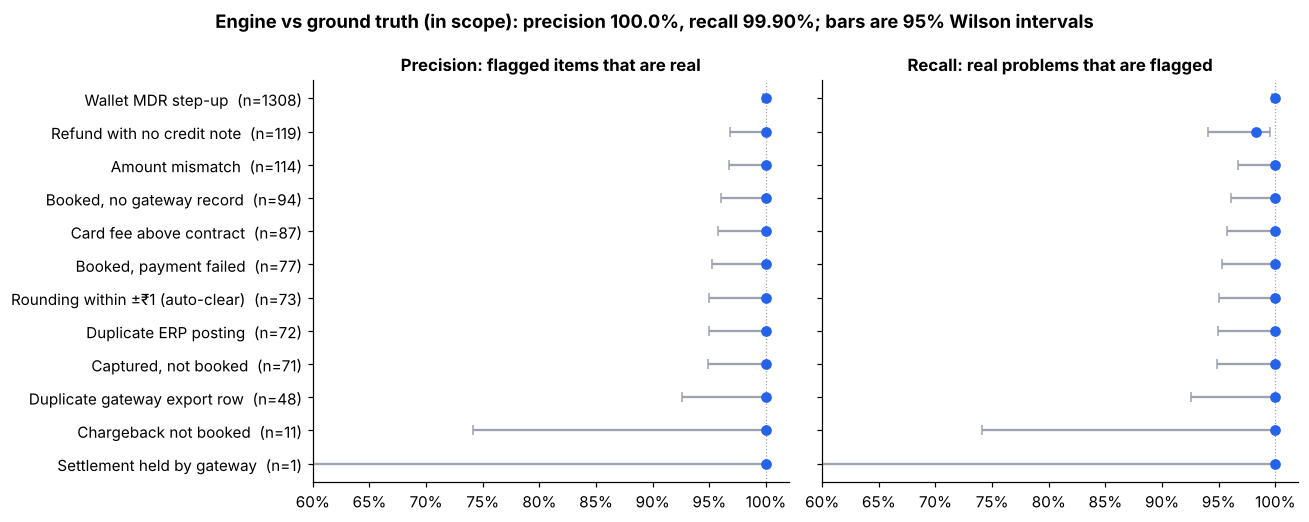

In [4]:
s = card[(card.view == "in_scope") & (card.issue != "ALL")].sort_values("labelled")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, m, title in [(axes[0], "precision", "Precision: flagged items that are real"),
                     (axes[1], "recall", "Recall: real problems that are flagged")]:
    y = np.arange(len(s))
    lo, hi = (s[m] - s[f"{m}_lo"]).clip(lower=0), (s[f"{m}_hi"] - s[m]).clip(lower=0)
    ax.errorbar(s[m], y, xerr=[lo, hi], fmt="o", color=ACCENT, ecolor=MUTED, capsize=3)
    ax.set_yticks(y, [f"{l}  (n={n})" for l, n in zip(s.label, s.labelled)])
    ax.set_xlim(0.6, 1.02); ax.axvline(1, color=MUTED, lw=0.8, ls=":")
    ax.set_title(title, fontsize=11)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle(f"Engine vs ground truth (in scope): precision {allr.precision:.1%}, recall {allr.recall:.2%}; "
             "bars are 95% Wilson intervals", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG / "08_scorecard.png", dpi=150, bbox_inches="tight"); plt.show()

## 2 · Every label that isn't a true positive

A miss is only useful if you know *why*. `scope_note` says why a label is out of scope; `engine_rule` says what the engine did with that key instead.

In [5]:
miss = det[det.outcome != "TP"].fillna({"engine_rule": "(key not in any engine table)"})
miss.groupby(["issue", "outcome", "scope_note", "engine_rule"]).size().rename("labels").reset_index()

,issue,outcome,scope_note,engine_rule,labels
0,amount_mismatch,FN,capture outside the UTC-dated export (before 05:30 IST 1 Oct or after 05:30 IST 1 Nov),R5_cutoff_erp,2
1,amount_mismatch,FN,"order dated before 1 Oct IST, not in the October ledger",(key not in any engine table),2
2,fee_overcharge_card,FN,capture outside the UTC-dated export (before 05:30 IST 1 Oct or after 05:30 IST 1 Nov),(key not in any engine table),1
3,fee_overcharge_wallet_rate_change,FN,capture is 1 Nov in IST (next period),R6_cutoff_gateway,5
4,fee_overcharge_wallet_rate_change,FN,capture outside the UTC-dated export (before 05:30 IST 1 Oct or after 05:30 IST 1 Nov),(key not in any engine table),6
5,gateway_only_not_booked,FN,capture outside the UTC-dated export (before 05:30 IST 1 Oct or after 05:30 IST 1 Nov),(key not in any engine table),2
6,ledger_only_no_gateway_record,FN,"order dated before 1 Oct IST, not in the October ledger",(key not in any engine table),1
7,ledger_only_payment_failed,FN,"order dated before 1 Oct IST, not in the October ledger",(key not in any engine table),1
8,refund_not_in_ledger,FN,,F5_cn_pending + R1_exact,2
9,refund_not_in_ledger,FN,refund is 1 Nov in IST (next period),F4_next_period + R1_exact,3


Reading the table:

- **Out-of-scope labels** are about activity the October review shouldn't flag: captures on 1 Nov in IST (the engine sends them to the November batch as timing), captures and refunds outside the UTC-dated export, and orders dated 30 Sep that never reached the October ledger. They aren't engine errors, but they matter: the "row not in the export" ones exist only because the gateway report is pulled by UTC date. **Pulling it by IST date removes them**, which is already a Day 2 recommendation.
- **In-scope misses** are refunds the engine parked as **CN pending** (rule F5, below). They are not lost; they sit in the timing queue with the action "confirm the credit note is posted in early November; break if not".

## 3 · What scoring changed in the engine

Scoring the Day 3 engine found **two real problems**, both fixed in SQL today:

**a) Refunds on the last day were all false positives.** The Day 3 engine flagged every refund with no October credit note as a break. Every false positive was a refund made on 31 Oct whose credit note finance posted, correctly, in November. The fix is rule **F5 CN pending**: a refund with no credit note yet, made within the *usual* posting lag of the period end, is timing, not a break. The lag isn't typed in; it's learned from the matched refund ↔ credit-note pairs:

In [6]:
sql("SELECT pairs, ROUND(median_h, 1) AS median_lag_h, ROUND(p99_h, 1) AS p99_lag_h, ROUND(max_h, 1) AS max_lag_h FROM cn_posting_lag")

,pairs,median_lag_h,p99_lag_h,max_lag_h
0,294,14.0,29.0,29.0


In [7]:
# Re-score the refund rule for a range of pending windows (0 h = the Day 3 rule)
rm = sql("SELECT r.*, p.period_end FROM refund_match r CROSS JOIN params p")
truth = pd.read_csv(ROOT / "data" / "truth" / "labels.csv")
scope = det[(det.issue == "refund_not_in_ledger")].set_index("key").scope_note
actual = set(truth.loc[truth.issue == "refund_not_in_ledger", "key"]) - set(scope[scope != ""].index)

no_cn = rm[rm.rule.isin(["F3_no_credit_note", "F5_cn_pending"])]
p99 = float(sql("SELECT p99_h FROM cn_posting_lag").p99_h[0])
rows = []
for h in [0, 6, 12, 18, 24, round(p99, 1), 36, 48, 72]:
    flagged = set(no_cn.loc[no_cn.ts_ist < no_cn.period_end - pd.Timedelta(hours=h), "order_id"])
    tp = len(flagged & actual); fp = len(flagged - actual); fn = len(actual - flagged)
    pending = len(no_cn) - len(flagged)
    rows.append(dict(window_h=h, flagged_breaks=len(flagged), parked_pending=pending, tp=tp, fp=fp, fn=fn,
                     precision=tp / (tp + fp), recall=tp / (tp + fn)))
sweep = pd.DataFrame(rows); sweep.round(4)

,window_h,flagged_breaks,parked_pending,tp,fp,fn,precision,recall
0,0.0,133,0,119,14,0,0.8947,1.0000
1,6.0,128,5,119,9,0,0.9297,1.0000
2,12.0,122,11,119,3,0,0.9754,1.0000
3,18.0,120,13,118,2,1,0.9833,0.9916
4,24.0,117,16,117,0,2,1.0000,0.9832
5,29.0,117,16,117,0,2,1.0000,0.9832
6,36.0,117,16,117,0,2,1.0000,0.9832
7,48.0,114,19,114,0,5,1.0000,0.9580
8,72.0,108,25,108,0,11,1.0000,0.9076


In [8]:
d3 = sweep[sweep.window_h == 0].iloc[0]; d4 = sweep[sweep.window_h == round(p99, 1)].iloc[0]
print(f"Day 3 rule (no window): precision {d3.precision:.4f}, recall {d3.recall:.4f}, {int(d3.fp)} false positives")
print(f"Day 4 rule (p99 window = {p99:.1f} h): precision {d4.precision:.4f}, recall {d4.recall:.4f}, "
      f"{int(d4.fp)} false positives, {int(d4.parked_pending)} refunds parked as pending")

Day 3 rule (no window): precision 0.8947, recall 1.0000, 14 false positives
Day 4 rule (p99 window = 29.0 h): precision 1.0000, recall 0.9832, 0 false positives, 16 refunds parked as pending


The trade-off is explicit: a longer window removes false alarms but parks more true breaks as "pending". The p99 window removes all the false positives and parks two real breaks, which is the better side to err on, because a pending item is re-checked within days while a false break wastes a reviewer's time *and* teaches them to ignore the list.

**b) A cross-period match the cash bridge couldn't explain.** This one did not show up in October at all. It appeared in the robustness run (section 5): on some generated months an order booked at 23:59 on 31 Oct was captured seconds later, on 1 Nov in IST. Leg 1 matched it as *exact*, but its cash is in the November payout, so the bridge was left with an unexplained line equal to that order. Rule **R0 cross-period** now sends these to timing. On the published month it changes nothing (0 such orders), which is exactly why testing on more than one month matters.

## 4 · Sensitivity of the ±₹1 amount tolerance

The tolerance decides what is rounding noise (auto-cleared) and what is an amount mismatch (a break). Too tight and reviewers chase paise; too loose and real discounts get waved through. Sweeping it over every key matched on order id:

In [9]:
l1 = sql("SELECT order_id, diff_inr FROM leg1_match WHERE rule IN ('R1_exact', 'R2_tolerance', 'R3_amount_mismatch')")
lab = truth.groupby("issue").key.apply(set)
rows = []
for tol in [0, 0.5, 1, 2, 5, 10, 20, 50]:
    auto = set(l1.loc[(l1.diff_inr != 0) & (l1.diff_inr.abs() <= tol), "order_id"])
    brk = set(l1.loc[l1.diff_inr.abs() > tol, "order_id"])
    mm, rd = lab["amount_mismatch"], lab["rounding_within_tolerance"]
    rows.append(dict(tolerance_inr=tol, auto_cleared=len(auto), breaks=len(brk),
                     rounding_left_as_breaks=len(rd & brk), discounts_auto_cleared=len(mm & auto),
                     mismatch_precision=len(brk & mm) / len(brk) if brk else np.nan,
                     mismatch_recall=len(brk & mm) / len(mm & set(l1.order_id))))
tol = pd.DataFrame(rows); tol.round(4)

,tolerance_inr,auto_cleared,breaks,rounding_left_as_breaks,discounts_auto_cleared,mismatch_precision,mismatch_recall
0,0.0,0,187,73,0,0.6096,1.0000
1,0.5,0,187,73,0,0.6096,1.0000
2,1.0,73,114,0,0,1.0000,1.0000
3,2.0,73,114,0,0,1.0000,1.0000
4,5.0,73,114,0,0,1.0000,1.0000
5,10.0,73,114,0,0,1.0000,1.0000
6,20.0,80,107,0,7,1.0000,0.9386
7,50.0,106,81,0,33,1.0000,0.7105


In [10]:
mm_keys = lab["amount_mismatch"] & set(l1.order_id)
smallest = l1[l1.order_id.isin(mm_keys)].diff_inr.abs().min()
largest_round = l1[l1.order_id.isin(lab["rounding_within_tolerance"])].diff_inr.abs().max()
print(f"largest rounding difference: ₹{largest_round:.2f}; smallest real discount: ₹{smallest:.2f}")
print(f"any tolerance from ₹{largest_round:.0f} up to just under ₹{smallest:.0f} gives the same perfect split")

largest rounding difference: ₹1.00; smallest real discount: ₹13.00
any tolerance from ₹1 up to just under ₹13 gives the same perfect split


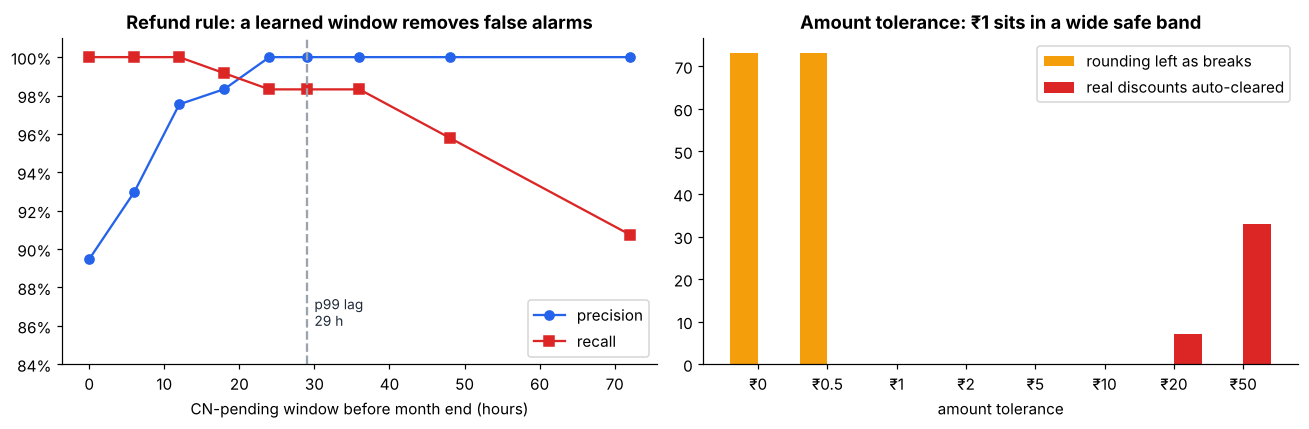

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(sweep.window_h, sweep.precision, "o-", color=ACCENT, label="precision")
ax.plot(sweep.window_h, sweep.recall, "s-", color=WARN, label="recall")
ax.axvline(p99, color=MUTED, ls="--"); ax.text(p99 + 1, 0.86, f"p99 lag\n{p99:.0f} h", color=INK, fontsize=9)
ax.set_xlabel("CN-pending window before month end (hours)"); ax.set_ylim(0.84, 1.01)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Refund rule: a learned window removes false alarms"); ax.legend(loc="lower right")
ax = axes[1]
x = np.arange(len(tol))
ax.bar(x - 0.2, tol.rounding_left_as_breaks, 0.4, color=AMBER, label="rounding left as breaks")
ax.bar(x + 0.2, tol.discounts_auto_cleared, 0.4, color=WARN, label="real discounts auto-cleared")
ax.set_xticks(x, [f"₹{t:g}" for t in tol.tolerance_inr]); ax.set_xlabel("amount tolerance")
ax.set_title("Amount tolerance: ₹1 sits in a wide safe band"); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "09_sensitivity.png", dpi=150, bbox_inches="tight"); plt.show()

## 5 · Robustness: 20 months the rules have never seen

`src/robustness.py` regenerates the month with seeds 101–120 (same documented rates; different orders, amounts, timings and which rows break), then runs cleaning, the SQL engine, the 7 integrity checks and the scorer on each. Nothing is re-tuned between runs. The results below are from the saved run in `data/output/robustness.csv` (rerun it with `python src/robustness.py 20`, about 1 minute).

In [12]:
rob = pd.read_csv(OUT / "robustness.csv")
a = rob[(rob.issue == "ALL") & (rob.view == "in_scope")]
print(f"{a.seed.nunique()} months | integrity checks pass in all: {bool(rob.integrity_checks_pass.all())} | "
      f"max |bridge residual|: ₹{rob.bridge_residual_inr.abs().max():.2f}")
display(a[["precision", "recall", "f1"]].agg(["mean", "min", "max"]).round(4))
per = (rob[rob.view == "in_scope"].groupby("label", sort=False)
       .agg(labelled=("labelled", "sum"), fp=("fp", "sum"), fn=("fn", "sum"),
            min_precision=("precision", "min"), min_recall=("recall", "min"), mean_recall=("recall", "mean"),
            fn_parked_as_cn_pending=("fn_in_cn_pending", "sum")))
per.loc["All types (micro-average)", "fn_parked_as_cn_pending"] = per.drop(index="All types (micro-average)").fn_parked_as_cn_pending.sum()
per.round(4)

20 months | integrity checks pass in all: True | max |bridge residual|: ₹0.00


,precision,recall,f1
mean,1.0,0.9975,0.9987
min,1.0,0.9963,0.9981
max,1.0,0.9990,0.9995


,labelled,fp,fn,min_precision,min_recall,mean_recall,fn_parked_as_cn_pending
label,,,,,,,
Duplicate ERP posting,1438,0,0,1.0,1.0000,1.0000,0
Duplicate gateway export row,979,0,0,1.0,1.0000,1.0000,0
Rounding within ±₹1 (auto-clear),1880,0,0,1.0,1.0000,1.0000,0
Amount mismatch,2414,0,0,1.0,1.0000,1.0000,0
"Booked, payment failed",1435,0,0,1.0,1.0000,1.0000,0
"Booked, no gateway record",1947,0,0,1.0,1.0000,1.0000,0
"Captured, not booked",1431,0,0,1.0,1.0000,1.0000,0
Refund with no credit note,2520,0,106,1.0,0.9310,0.9575,106
Card fee above contract,1719,0,0,1.0,1.0000,1.0000,0


In [13]:
r = rob[(rob.view == "in_scope") & (rob.issue == "refund_not_in_ledger")]
print(f"refund misses across 20 months: {int(r.fn.sum())}, of which parked as CN pending: {int(r.fn_in_cn_pending.sum())}")

refund misses across 20 months: 106, of which parked as CN pending: 106


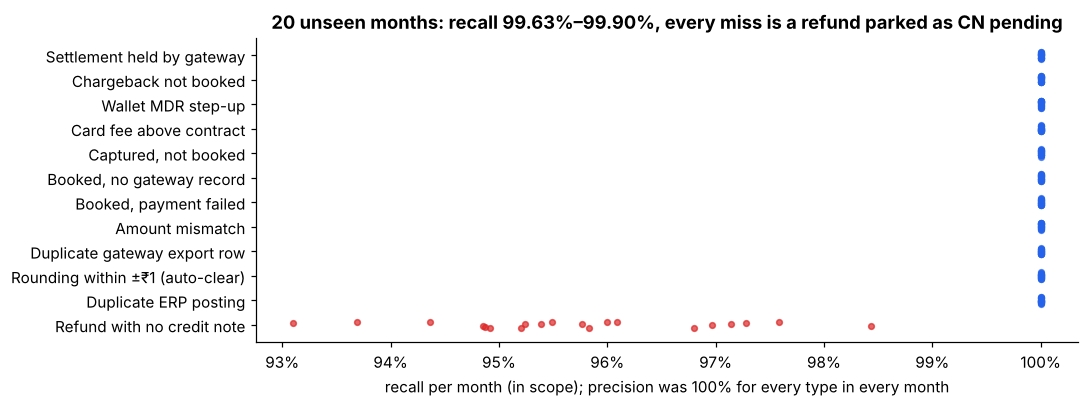

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.8))
types = per.drop(index="All types (micro-average)").sort_values("mean_recall")
rr = rob[(rob.view == "in_scope") & (rob.issue != "ALL")]
for i, lbl in enumerate(types.index):
    v = rr[rr.label == lbl].recall.values
    ax.scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(v)),
               s=14, color=WARN if v.min() < 0.99 else ACCENT, alpha=0.7)
ax.set_yticks(range(len(types)), types.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("recall per month (in scope); precision was 100% for every type in every month")
ax.set_title(f"20 unseen months: recall {a.recall.min():.2%}–{a.recall.max():.2%}, "
             "every miss is a refund parked as CN pending")
plt.tight_layout(); plt.savefig(IMG / "10_robustness.png", dpi=150, bbox_inches="tight"); plt.show()

## Summary

- **Precision is 100% for every exception type**, in October and in all 20 unseen months: nothing on the work list is a false alarm.
- **Recall in scope is above 99.6% in every month.** The only misses are refunds made in the last ~29 hours of the month that the engine deliberately parks as *CN pending* and re-checks in November, so no real problem is dropped silently.
- **Scoring changed the engine twice**: the learned CN-pending window (F5) removed every refund false positive, and the cross-period rule (R0) fixed a bridge residual that only showed up on other months.
- **The ±₹1 tolerance is not fragile**: any value between the largest rounding difference and the smallest real discount gives the same split.
- The out-of-scope labels point at one process fix: **pull the gateway report by IST date**.

Exact figures are printed above and repeated in the README.

**Next (Day 5):** the reconciliation dashboard.